Validación y escenarios condicionales
Leer PLAN_Y_PROTOCOLO.md. La selección usa solo desarrollo; 2023–2025 fueron vistos previamente, por lo que estos resultados son retrospectivos y exploratorios. Una diferencia de predicciones no es un efecto causal. Orden: preparación, pruebas previas, modelos, pruebas de resultados, tablas y gráficas.

In [1]:
from pathlib import Path
import sys,json
BASE=Path.cwd()
if not (BASE/'PLAN_Y_PROTOCOLO.md').exists():BASE=BASE/'objetivo4_validacion_escenarios'
sys.path.insert(0,str(BASE/'fuentes'))
from tests import run as probar
print('Pruebas previas:',probar(False))

test_folds (tests.Reglas.test_folds) ... ok
test_metricas_invalidas (tests.Reglas.test_metricas_invalidas) ... ok
test_metricas_manual (tests.Reglas.test_metricas_manual) ... ok
test_preparacion (tests.Reglas.test_preparacion) ... ok
test_seleccion_predefinida (tests.Reglas.test_seleccion_predefinida) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.007s

OK
Pruebas previas: 5


Ejecución de los modelos
La primera ejecución realiza los ajustes. Las siguientes lecturas reutilizan la entrega cerrada. Para una reproducción nueva, copiar esta carpeta y eliminar únicamente los resultados de la copia, conservando originales. No modificar protocolo ni fuentes para mejorar métricas.

In [2]:
from modelos import run,OUT
if (OUT/'EJECUCION.json').exists():
    print('Resultados anteriores de esta entrega; no se repitieron ajustes.')
    resultado=json.loads((OUT/'EJECUCION.json').read_text())
else:resultado=run()
print(json.dumps(resultado,ensure_ascii=False,indent=2))

corte2023 prom_punt_global temporal {'base': 'ElasticNet_14', 'ipm': 'Lasso_07', 'componentes': 'ElasticNet_13'} fits 183
corte2023 prom_punt_global loyo {'base': 'Lasso_07', 'ipm': 'Lasso_07', 'componentes': 'Lasso_06'} fits 411
corte2023 mat34 temporal {'base': 'Ridge_00', 'ipm': 'Ridge_02', 'componentes': 'ElasticNet_12'} fits 594
corte2023 mat34 loyo {'base': 'Ridge_00', 'ipm': 'Ridge_00', 'componentes': 'Ridge_00'} fits 822
corte2022 prom_punt_global temporal {'base': 'ElasticNet_13', 'ipm': 'ElasticNet_14', 'componentes': 'ElasticNet_13'} fits 960
corte2022 prom_punt_global loyo {'base': 'Lasso_07', 'ipm': 'Lasso_07', 'componentes': 'Ridge_03'} fits 1143
corte2022 mat34 temporal {'base': 'Ridge_00', 'ipm': 'Ridge_02', 'componentes': 'ElasticNet_12'} fits 1281
corte2022 mat34 loyo {'base': 'Ridge_00', 'ipm': 'Ridge_01', 'componentes': 'Ridge_00'} fits 1464
Territorio omitido 05 fits 1785
Territorio omitido 08 fits 1968
Territorio omitido 11 fits 2151
Territorio omitido 13 fits 233

In [3]:
print('Pruebas completas:',probar(True))
import pandas as pd
m=pd.read_csv(OUT/'metricas.csv',dtype={'anio':str})
print(m.query('exercise=="corte2023" and method=="temporal" and target=="prom_punt_global"').to_string(index=False))
s=pd.read_csv(OUT/'escenarios.csv')
print(s.groupby('escenario').agg(admitidos=('admitido','sum'),total=('admitido','size')).to_string())

test_folds (tests.Reglas.test_folds) ... ok
test_metricas_invalidas (tests.Reglas.test_metricas_invalidas) ... ok
test_metricas_manual (tests.Reglas.test_metricas_manual) ... ok
test_preparacion (tests.Reglas.test_preparacion) ... ok
test_seleccion_predefinida (tests.Reglas.test_seleccion_predefinida) ... ok
test_escenarios (tests.Resultados.test_escenarios) ... ok
test_exclusion_territorial (tests.Resultados.test_exclusion_territorial) ... ok
test_metricas_csv (tests.Resultados.test_metricas_csv) ... ok
test_presupuesto (tests.Resultados.test_presupuesto) ... ok

----------------------------------------------------------------------
Ran 9 tests in 0.174s

OK
Pruebas completas: 9
 exercise   method           target                 spec     anio  n       MAE      RMSE     sesgo       R2
corte2023 temporal prom_punt_global                 base     2024 33 11.998185 14.209312 -6.316356 0.304532
corte2023 temporal prom_punt_global                 base     2025 33 13.077892 15.230874 -7.607

In [4]:
from graficas import run as graficar
print(graficar())

['figuras/errores_2024_2025.png', 'figuras/escenarios_admitidos.png']


In [5]:
from resumen import run as diagnosticar
print(diagnosticar())

{
  "variacion_anual_reduccion_pp": {
    "count": 165.0,
    "mean": 1.814545454545454,
    "std": 3.8841964756743192,
    "min": -10.600000000000009,
    "25%": -0.3000000000000007,
    "50%": 1.4000000000000004,
    "75%": 3.8000000000000007,
    "max": 18.300000000000004
  },
  "fraccion_descensos_1_3_5": {
    "1": 0.6060606060606061,
    "3": 0.3575757575757576,
    "5": 0.1696969696969697
  },
  "motivos_rechazos": {
    "rango_ipm_territorio": 148,
    "base:rango_ipm_territorio": 130,
    "distancia_conjunta": 35,
    "rango_global_ipm": 21,
    "base:distancia_conjunta": 10,
    "ipm_invalido": 6,
    "base:rango_global_ipm": 5
  },
  "matematicas_predicciones_fuera_0_100": 0,
  "intervalo2019_2021_no_anual": true
}
{'variacion_anual_reduccion_pp': {'count': 165.0, 'mean': 1.814545454545454, 'std': 3.8841964756743192, 'min': -10.600000000000009, '25%': -0.3000000000000007, '50%': 1.4000000000000004, '75%': 3.8000000000000007, 'max': 18.300000000000004}, 'fraccion_descensos_1_

Verificación final de la publicación
Los modelos anteriores no se vuelven a ajustar. Se excluyen de la gráfica los escenarios sin reducción efectiva y se comprueban los datos de cada figura contra los resultados originales. Las diez pruebas finales incluyen estas comprobaciones adicionales.

test_folds (tests.Reglas.test_folds) ... ok
test_metricas_invalidas (tests.Reglas.test_metricas_invalidas) ... ok
test_metricas_manual (tests.Reglas.test_metricas_manual) ... ok
test_preparacion (tests.Reglas.test_preparacion) ... ok
test_seleccion_predefinida (tests.Reglas.test_seleccion_predefinida) ... ok
test_escenarios (tests.Resultados.test_escenarios) ... ok
test_exclusion_territorial (tests.Resultados.test_exclusion_territorial) ... ok
test_graficas (tests.Resultados.test_graficas) ... ok
test_metricas_csv (tests.Resultados.test_metricas_csv) ... ok
test_presupuesto (tests.Resultados.test_presupuesto) ... ok

----------------------------------------------------------------------
Ran 10 tests in 0.673s

OK
Pruebas finales aprobadas: 10


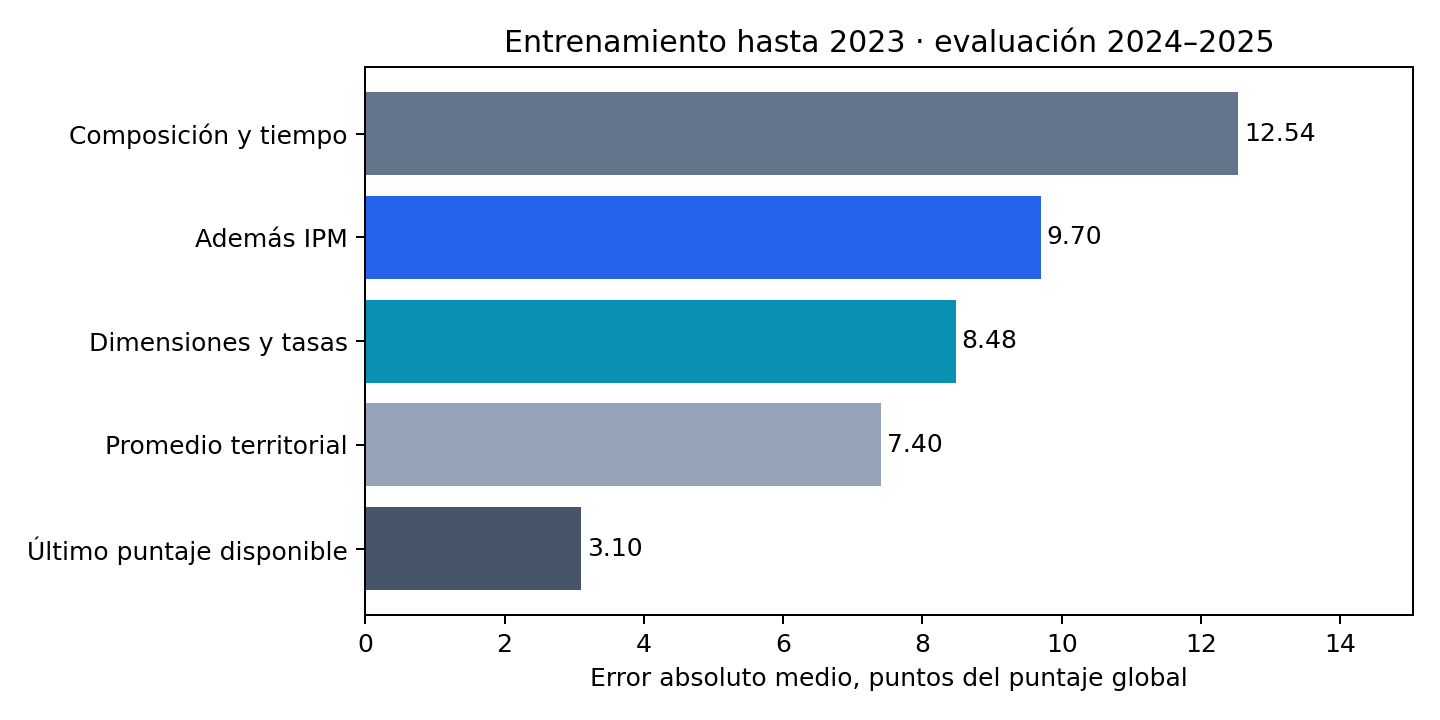

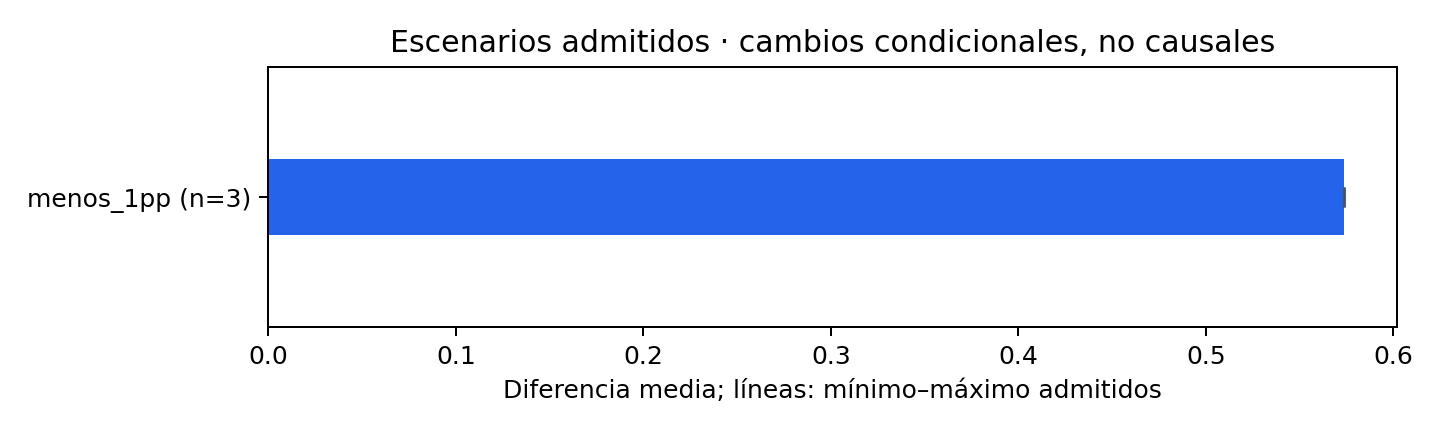

In [7]:
from pathlib import Path
import sys
BASE=Path.cwd()
if not (BASE/'PLAN_Y_PROTOCOLO.md').exists():BASE=BASE/'objetivo4_validacion_escenarios'
sys.path.insert(0,str(BASE/'fuentes'))
from tests import run as pruebas_finales
print('Pruebas finales aprobadas:',pruebas_finales(True))